# Phenix — Détection contextuelle, validation exploratoire
Le modèle apprend des relations sur les données normales. Le seuil est fixé sur la calibration normale (quantile 99,5 %). Aucun ajustement après consultation de la validation et aucun scoring du test dans cet essai.

Placer ce notebook dans backend/ML/notebooks puis Exécuter tout. Dépendances locales : pandas, numpy, matplotlib. Les résultats fournis sont synthétiques et ne démontrent pas une performance sur les logs réels.


In [5]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
EXPERIMENT = "local-v2-context"
roots = [candidate for parent in [Path.cwd(), *Path.cwd().parents] for candidate in [parent, parent / "backend" / "ML"] if (candidate / "experiments" / EXPERIMENT / "metrics.json").is_file()]
if not roots:
    raise FileNotFoundError("Vérifier EXPERIMENT et placer le notebook dans backend/ML/notebooks")
EXP_DIR = roots[0] / "experiments" / EXPERIMENT
report = json.loads((EXP_DIR / "metrics.json").read_text(encoding="utf-8"))
threshold = report["metadata"]["threshold"]
rows = []
for name, result in report["splits"].items():
    rows.append({"Période": name, **{key: result[key] for key in ["true_positive", "false_positive", "false_negative", "precision", "recall"]}})
display(pd.DataFrame(rows).set_index("Période"))


,true_positive,false_positive,false_negative,precision,recall
Période,,,,,
train,0,1,0,0.000000,0.00000
calibration,133,50,7,0.726776,0.95000
validation,117,1,6,0.991525,0.95122


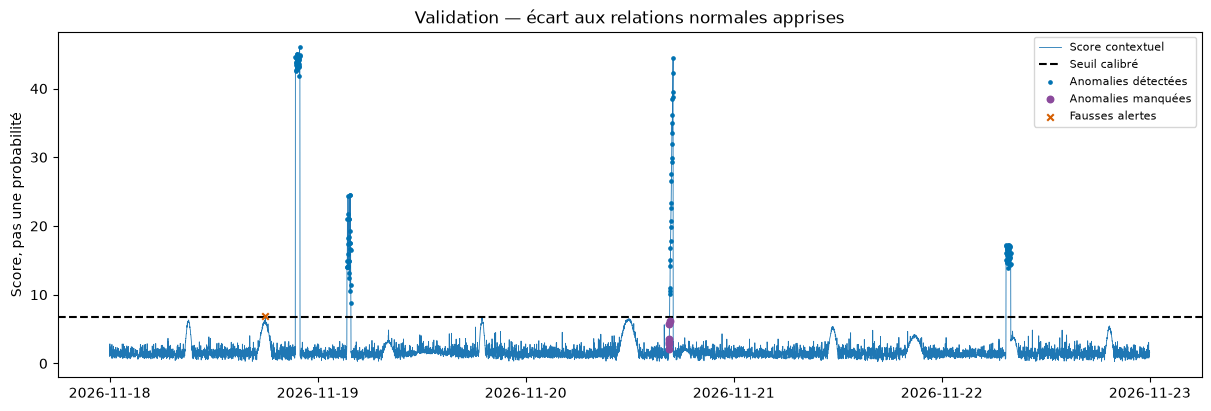

,start,end,minutes,detected,delay_minutes
0,2026-11-18 21:26:00,2026-11-18 21:57:00,32,True,0
1,2026-11-19 03:23:00,2026-11-19 03:50:00,28,True,0
2,2026-11-20 16:31:00,2026-11-20 17:00:00,30,True,6
3,2026-11-22 07:25:00,2026-11-22 07:57:00,33,True,0


In [6]:
df = pd.read_csv(EXP_DIR / "validation_predictions.csv", parse_dates=["timestamp"])
y = df.is_anomaly.eq(1)
p = df.predicted_anomaly.eq(1)
s = report["splits"]["validation"]
assert int((y & p).sum()) == s["true_positive"]
assert int((~y & p).sum()) == s["false_positive"]
assert int((y & ~p).sum()) == s["false_negative"]
assert np.array_equal(p.to_numpy(), (df.anomaly_score > threshold).to_numpy())
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.plot(df.timestamp, df.anomaly_score, lw=.6, label="Score contextuel")
ax.axhline(threshold, color="black", ls="--", label="Seuil calibré")
for mask, label, color, marker in [(y & p, "Anomalies détectées", "#0072B2", "."), (y & ~p, "Anomalies manquées", "#8B4A9C", "o"), (~y & p, "Fausses alertes", "#D55E00", "x")]:
    ax.scatter(df.loc[mask, "timestamp"], df.loc[mask, "anomaly_score"], label=label, color=color, marker=marker, s=22, zorder=3)
ax.set(title="Validation — écart aux relations normales apprises", ylabel="Score, pas une probabilité")
ax.legend(fontsize=8)
plt.show()
display(pd.DataFrame(s["episodes"]))


## Lecture des résultats
Comparer avec la V2 sur la même validation : 0/123 minutes détectées et 20 minutes de fausses alertes pour Isolation Forest. Ne pas comparer directement les valeurs des scores entre les deux modèles.

Les épisodes, leurs causes et les actions Ansible ne sont pas appris ici. La régression quadratique constitue une hypothèse de modélisation ; les données synthétiques présentent justement des relations régulières avec le trafic. Il reste à vérifier cette hypothèse sur l'environnement réel et sur de nouveaux scénarios indépendants. Cette variante ne tient pas encore compte de l'historique temporel.
